# COMP6008 Group 17 - Solar Energy Models

In [68]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
from collections import deque, namedtuple
from gymnasium import spaces

from IPython.display import display

import profiles as P
from energy_env import EnergyEnv, decode_action

# if GPU is to be used
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)

## Environment

### Profiles

In [69]:
%%writefile profiles.py
"""
profiles.py - Synthetic hourly data for the home energy scheduling environment.

Everything here is a 24-value array (one value per hour, index 0 = midnight).
All numbers are illustrative assumptions for a typical Perth household;
state them as assumptions in the report.

Usage:
    from profiles import sample_day
    day = sample_day(rng)          # rng = np.random.default_rng(seed)
    day["solar"], day["load"], day["price"], ...
"""

import numpy as np

HOURS = np.arange(24)

# ---------------------------------------------------------------------------
# Solar generation (kW) - bell curve between sunrise and sunset, scaled by weather
# ---------------------------------------------------------------------------
SOLAR_PEAK_KW = 5.0            # roughly a 6.6 kW rooftop system on a clear day
SUNRISE, SUNSET = 6, 18

WEATHER_TYPES = ["sunny", "cloudy", "rainy"]
WEATHER_PROBS = [0.6, 0.3, 0.1]                          # Perth is mostly sunny
WEATHER_SCALE = {"sunny": 1.0, "cloudy": 0.5, "rainy": 0.2}


def solar_profile(weather, rng=None, noise=0.1):
    """Hourly solar output (kW) for a given weather type."""
    curve = np.zeros(24)
    daylight = (HOURS >= SUNRISE) & (HOURS <= SUNSET)
    # half-sine shape: 0 at sunrise/sunset, peak at midday
    curve[daylight] = np.sin(np.pi * (HOURS[daylight] - SUNRISE) / (SUNSET - SUNRISE))
    solar = SOLAR_PEAK_KW * WEATHER_SCALE[weather] * curve
    if rng is not None:                                   # small random variation
        solar *= 1 + rng.normal(0, noise, 24)
    return np.clip(solar, 0, None)


# ---------------------------------------------------------------------------
# Household base load (kW) - things we do NOT control (fridge, lights, cooking)
# 4x6 hours to baseline.
# ---------------------------------------------------------------------------
BASE_LOAD = np.array([
    0.4, 0.3, 0.3, 0.3, 0.3, 0.4,    # 00-05 night
    0.8, 1.2, 1.0, 0.6, 0.5, 0.5,    # 06-11 morning peak
    0.6, 0.5, 0.5, 0.6, 0.9, 1.5,    # 12-17 afternoon
    2.0, 1.8, 1.4, 1.0, 0.7, 0.5,    # 18-23 evening peak
])


def load_profile(rng=None, noise=0.1):
    load = BASE_LOAD.copy()
    if rng is not None:
        load *= 1 + rng.normal(0, noise, 24)
    return np.clip(load, 0.1, None)


# ---------------------------------------------------------------------------
# Time-of-use tariff ($/kWh) - cheap midday, expensive evening peak
# ---------------------------------------------------------------------------
PRICE_OFFPEAK, PRICE_MIDDAY, PRICE_PEAK = 0.25, 0.10, 0.55
FEED_IN_PRICE = 0.03            # paid for exporting solar to the grid


def price_profile():
    price = np.full(24, PRICE_OFFPEAK)
    price[9:15] = PRICE_MIDDAY       # 9am-3pm
    price[15:21] = PRICE_PEAK        # 3pm-9pm
    return price


# ---------------------------------------------------------------------------
# Home battery and EV
# ---------------------------------------------------------------------------
BATTERY = {"capacity_kwh": 10.0, "max_rate_kw": 5.0, "efficiency": 0.95}

EV = {
    "capacity_kwh": 60.0,
    "max_rate_kw": 7.0,
    "arrive_hour": 18,          # plugged in from 6pm ...
    "depart_hour": 7,           # ... until 7am next morning
    "arrive_soc": 0.4,          # 40% charge when it gets home
    "target_soc": 0.8,          # needs 80% by departure (penalty if not)
}


def ev_plugged_in():
    """Boolean array: True for hours the EV is at home and can charge."""
    return (HOURS >= EV["arrive_hour"]) | (HOURS < EV["depart_hour"])


# ---------------------------------------------------------------------------
# Shiftable appliances - must run once per day, agent chooses when
# ---------------------------------------------------------------------------
APPLIANCES = {
    "washing_machine": {"power_kw": 1.0, "duration_h": 2, "earliest": 7,  "deadline": 22},
    "dishwasher":      {"power_kw": 1.2, "duration_h": 2, "earliest": 8,  "deadline": 23},
}


# ---------------------------------------------------------------------------
# One episode = one simulated day
# ---------------------------------------------------------------------------
def sample_day(rng, weather=None):
    """Return all profiles for one day. Weather is random unless given."""
    if weather is None:
        weather = rng.choice(WEATHER_TYPES, p=WEATHER_PROBS)
    return {
        "weather": weather,
        "solar": solar_profile(weather, rng),
        "load": load_profile(rng),
        "price": price_profile(),
        "feed_in": FEED_IN_PRICE,
        "ev_plugged_in": ev_plugged_in(),
    }

Overwriting profiles.py


### EnergyEnv

In [70]:
%%writefile energy_env.py
"""
energy_env.py - Home energy scheduling environment (Gymnasium).

One episode = one day, 24 hourly steps, from 07:00 to 07:00 the next morning.
Starting at 07:00 means the EV's deadline (charged by 07:00 departure) falls
exactly at the end of the episode.

Observation (15 values, fixed order - do not change without telling the group):
    0 hour_sin, 1 hour_cos, 2 battery_soc, 3 ev_soc, 4 ev_plugged_in,
    5 solar_now, 6 solar_next, 7 load_now, 8 price_now, 9 price_next,
    10 sunny, 11 cloudy, 12 rainy, 13 washer_pending, 14 dishwasher_pending

Action (Discrete 12):  action = battery * 4 + ev * 2 + appliance
    battery:   0 = charge, 1 = idle, 2 = discharge
    ev:        0 = wait,   1 = charge
    appliance: 0 = defer,  1 = start next pending appliance
"""

import numpy as np
import gymnasium as gym
from gymnasium import spaces

import profiles as P

START_HOUR = 7
EV_PENALTY_PER_KWH = 1.0      # $ per kWh the EV is short at departure
APPLIANCE_PENALTY = 2.0       # $ if an appliance misses its deadline
SOLAR_MAX = 7.5               # observation-space bound on solar (kW)


def decode_action(action):
    """Split the single action number into its three parts."""
    action = int(action)
    return action // 4, (action // 2) % 2, action % 2


class EnergyEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, weather=None):
        super().__init__()
        if weather not in (None, *P.WEATHER_TYPES):
            raise ValueError("weather must be sunny, cloudy or rainy")
        self.fixed_weather = weather          # None = random weather each episode
        self.appliance_names = list(P.APPLIANCES)

        low = np.array([-1, -1] + [0.0] * 15, dtype=np.float32)
        high = np.array([1, 1, 1, 1, 1,
                         SOLAR_MAX, SOLAR_MAX, 5.0,
                         P.PRICE_PEAK, P.PRICE_PEAK,
                         1, 1, 1, 1, 1,
                         2, 2], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)
        self.action_space = spaces.Discrete(12)
        self.t = 24

    # ------------------------------------------------------------------ reset
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                    # sets self.np_random
        self.day = P.sample_day(self.np_random, self.fixed_weather)
        self.t = 0                                   # step counter 0..23
        self.battery_soc = 0.5
        self.ev_soc = P.EV["arrive_soc"]
        # per appliance: "pending" (not started), "running", "done", "missed"
        self.app_status = {n: "pending" for n in self.appliance_names}
        self.app_hours_left = {n: 0 for n in self.appliance_names}
        return self._obs(), {}

    # ------------------------------------------------------------------- step
    def step(self, action):
        if self.t >= 24:
            raise RuntimeError("Call reset() before starting another day")
        if not self.action_space.contains(action):
            raise ValueError("Action must be an integer from 0 to 11")
        h = self.hour
        b_act, ev_act, app_act = decode_action(int(action))
        solar = self.day["solar"][h]
        load = self.day["load"][h]
        price = self.day["price"][h]
        penalty = 0.0

        # 1. Appliances: start the next pending one if allowed, then run them
        if app_act == 1:
            for n in self.appliance_names:
                spec = P.APPLIANCES[n]
                latest_start = spec["deadline"] - spec["duration_h"]
                if self.app_status[n] == "pending" and spec["earliest"] <= h <= latest_start:
                    self.app_status[n] = "running"
                    self.app_hours_left[n] = spec["duration_h"]
                    break
        appliance_kwh = 0.0
        for n in self.appliance_names:
            if self.app_status[n] == "running":
                appliance_kwh += P.APPLIANCES[n]["power_kw"]
                self.app_hours_left[n] -= 1
                if self.app_hours_left[n] == 0:
                    self.app_status[n] = "done"

        # 2. EV arrives home at 18:00 with a fixed charge level
        if h == P.EV["arrive_hour"]:
            self.ev_soc = P.EV["arrive_soc"]
        ev_kwh = 0.0
        if ev_act == 1 and self.day["ev_plugged_in"][h]:
            ev_kwh = min(P.EV["max_rate_kw"], (1 - self.ev_soc) * P.EV["capacity_kwh"])
            self.ev_soc += ev_kwh / P.EV["capacity_kwh"]

        # 3. Home battery (efficiency loss on the way in and out)
        cap, rate, eff = (P.BATTERY[k] for k in ("capacity_kwh", "max_rate_kw", "efficiency"))
        battery_before = self.battery_soc * cap
        batt_in = batt_out = 0.0
        if b_act == 0:                                   # charge
            batt_in = min(rate, (1 - self.battery_soc) * cap / eff)
            self.battery_soc += batt_in * eff / cap
        elif b_act == 2:                                 # discharge
            drawn = min(rate, self.battery_soc * cap)
            self.battery_soc -= drawn / cap
            batt_out = drawn * eff
        self.battery_soc = float(np.clip(self.battery_soc, 0, 1))

        # 4. Energy balance: positive = buy from grid, negative = sell
        net = load + appliance_kwh + ev_kwh + batt_in - solar - batt_out
        grid_import, grid_export = max(net, 0.0), max(-net, 0.0)
        cost = grid_import * price - grid_export * self.day["feed_in"]

        # 5. Penalties: appliance past its latest start time
        for n in self.appliance_names:
            spec = P.APPLIANCES[n]
            latest_start = spec["deadline"] - spec["duration_h"]
            if self.app_status[n] == "pending" and h >= latest_start:
                self.app_status[n] = "missed"
                penalty += APPLIANCE_PENALTY

        # 6. Advance time; at 07:00 the EV leaves - penalise any shortfall
        self.t += 1
        terminated = self.t == 24
        shortfall = 0.0
        if terminated:
            shortfall = max(P.EV["target_soc"] - self.ev_soc, 0) * P.EV["capacity_kwh"]
            penalty += EV_PENALTY_PER_KWH * shortfall

        reward = -(cost + penalty)
        info = {"cost": cost, "penalty": penalty, "grid_import": grid_import,
                "grid_export": grid_export, "hour": h, "weather": self.day["weather"],
                "solar": solar, "load": load, "appliance_kwh": appliance_kwh,
                "ev_kwh": ev_kwh, "battery_in": batt_in, "battery_out": batt_out,
                "battery_before": battery_before,
                "battery_after": self.battery_soc * cap,
                "ev_soc": self.ev_soc, "ev_shortfall": shortfall,
                "missed_jobs": sum(1 for n in self.appliance_names
                                   if self.app_status[n] == "missed")}
        return self._obs(), reward, terminated, False, info

    # --------------------------------------------------------------- helpers
    @property
    def hour(self):
        return (START_HOUR + self.t) % 24

    def _obs(self):
        h = self.hour
        nxt = (h + 1) % 24
        weather_onehot = [float(self.day["weather"] == w) for w in P.WEATHER_TYPES]
        pending = [float(self.app_status[n] == "pending") for n in self.appliance_names]
        hours_left = [float(self.app_hours_left[n]) for n in self.appliance_names]
        obs = [
            np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
            self.battery_soc, self.ev_soc, float(self.day["ev_plugged_in"][h]),
            self.day["solar"][h], self.day["solar"][nxt], self.day["load"][h],
            self.day["price"][h], self.day["price"][nxt],
            *weather_onehot, *pending, *hours_left,
        ]
        return np.clip(np.array(obs, dtype=np.float32),
                       self.observation_space.low, self.observation_space.high)

Overwriting energy_env.py


### Helpers

## Agents

### Helpers

In [71]:
def epsilon_greedy(Q, state, epsilon, rng):
    """[L6] Random action with probability epsilon, otherwise the best action (ties broken randomly)."""
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))
    q = Q[state]
    best_actions = np.flatnonzero(q == q.max())
    return int(rng.choice(best_actions))

def epsilon_at(episode, episodes, decay=True, eps_start=1.0, eps_end=0.05, eps_decay_frac=0.8):
    """Linear decay of epsilon from eps_start to eps_end over decay_steps."""
    if not decay:
        return eps_start
    decay_steps = int(eps_decay_frac * episodes)
    return max(eps_end, eps_start - (eps_start - eps_end) * episode / decay_steps)

### Discretiser

In [72]:
# ---------------------------------------------------------------------------
# Tabular Dimensions
# ---------------------------------------------------------------------------
N_HOUR = 24         # 24 hours of the day (0..23, recovered from sin/cos)
N_BATT = 5          # 5 battery SOC bins (0-20%, 20-40%, 40-60%, 60-80%, 80-100%)
N_EV = 4            # 4 EV SOC bins (<50%, 50-65%, 65-80%, >=80% target)
N_WEATHER = 3       # 3 weather types (sunny=0, cloudy=1, rainy=2)
N_WASHER = 3        # 3 washer states (0=pending, 1=running, 2=done/missed)
N_DISHWASHER = 3    # 3 dishwasher states (0=pending, 1=running, 2=done/missed

NUM_STATES = N_HOUR * N_BATT * N_EV * N_WEATHER * N_WASHER * N_DISHWASHER + 1
TERMINAL = NUM_STATES - 1
NUM_ACTIONS = 12
EV_BIN_EDGES = [0.5, 0.65, 0.8]

def discretise(obs):
    """Map the 17-value observation to a single state index 0..NUM_STATES-1."""
    hour = round(np.arctan2(obs[0], obs[1]) * 24 / (2 * np.pi)) % 24
    batt = min(int(obs[2] * N_BATT), N_BATT - 1)
    ev = int(np.searchsorted(EV_BIN_EDGES, float(obs[3]), side="right"))
    weather = int(np.argmax(obs[10:13]))
    # each job: 0 pending, 1 running, 2 finished or already penalised
    washer = 0 if obs[13] else (1 if obs[15] > 0 else 2)
    dishwasher = 0 if obs[14] else (1 if obs[16] > 0 else 2)
    return int(((((hour * N_BATT + batt) * N_EV + ev) * N_WEATHER + weather) * N_WASHER + washer) * N_DISHWASHER + dishwasher)

print("Number of states:", NUM_STATES)

Number of states: 12961


### Q-Learning: Agent

In [73]:
def Qlearning(env, gamma=1.0, alpha=0.3, eps_start=1.0, eps_end=0.05,
              eps_decay_frac=0.8, max_episodes=50000, seed=0):
    rng = np.random.default_rng(seed)

    # [L1] initialise action-value table
    Q = np.zeros((NUM_STATES, NUM_ACTIONS))
    episode_returns = np.zeros(max_episodes)

    # [L2] loop over episodes (one episode = one simulated day)
    for e in range(max_episodes):
        # [L3] linearly decaying epsilon (GLIE-style), constant after eps_decay_frac of training
        epsilon = max(eps_end, eps_start - (eps_start - eps_end) * e / (eps_decay_frac * max_episodes))

        # [L4] reset and discretise the first observation
        obs, _ = env.reset(seed=seed * 1_000_000 + e)
        state = discretise(obs)
        terminated = truncated = False
        G = 0.0

        # [L5] loop over the 24 hourly steps
        while not (terminated or truncated):
            # [L6] behaviour policy: epsilon-greedy w.r.t. Q
            action = epsilon_greedy(Q, state, epsilon, rng)

            # [L7] act, observe reward and next observation
            next_obs, reward, terminated, truncated, _ = env.step(action)

            # [L8] discretise the next observation
            next_state = discretise(next_obs)

            # [L9] TD target; Q(terminal, .) = 0 so there is no bootstrap at the end of the day
            target = reward if terminated else reward + gamma * np.max(Q[next_state])

            # [L10] Q-learning update
            Q[state, action] += alpha * (target - Q[state, action])

            # [L11] move to the next state
            state = next_state
            G += reward

        episode_returns[e] = G

    # [L12] greedy target policy
    pi = np.argmax(Q, axis=1)
    return Q, pi, episode_returns

### Dyna-Q: Agent

In [74]:
class TableLookup:
    """Practical 6 stochastic model, storing only observed state-action entries."""
    def __init__(self):
        self.entries, self.pairs = {}, []

    def learn(self, state, action, reward, next_state):
        key = (state,action)
        if key not in self.entries:
            self.entries[key] = {"count":0, "reward":0., "next":{}}
            self.pairs.append(key)
        entry = self.entries[key]
        entry["count"] += 1
        entry["reward"] += (reward-entry["reward"])/entry["count"]
        counts = entry["next"]
        counts[next_state] = counts.get(next_state,0)+1

    def simulate(self, rng):
        state, action = self.pairs[int(rng.integers(len(self.pairs)))]
        entry = self.entries[state,action]
        successors = list(entry["next"])
        probabilities = np.array(list(entry["next"].values()),dtype=float)/entry["count"]
        next_state = successors[int(rng.choice(len(successors),p=probabilities))]
        return state, action, entry["reward"], next_state


def DynaQ(env, gamma=1., alpha=.3, max_episodes=15000, seed=0, planning_steps=5):
    Q = np.zeros((NUM_STATES,NUM_ACTIONS))  # [D1]
    returns = np.zeros(max_episodes)
    model = TableLookup()
    rng = np.random.default_rng(seed)
    planning_rng = np.random.default_rng(seed+10_000)
    for episode in range(max_episodes):
        epsilon = epsilon_at(episode,max_episodes)
        obs, _ = env.reset(seed=seed*1_000_000+episode)
        state = discretise(obs)
        while True:
            action = epsilon_greedy(Q,state,epsilon,rng)  # [D2]
            obs, reward, terminated, truncated, _ = env.step(action)  # [D3]
            next_state = TERMINAL if terminated else discretise(obs)
            target = reward if terminated else reward+gamma*Q[next_state].max()
            Q[state,action] += alpha*(target-Q[state,action])  # [D4] Direct learning.
            model.learn(state,action,reward,next_state)  # [D5] Learn the model.
            for _ in range(planning_steps):
                s, a, r, next_s = model.simulate(planning_rng)  # [D6]
                y = r if next_s == TERMINAL else r+gamma*Q[next_s].max()
                Q[s,a] += alpha*(y-Q[s,a])  # [D7] Planning update.
            returns[episode] += reward
            state = next_state  # [D8] Keep real state separate from planning states.
            if terminated or truncated:
                break
    return Q, np.argmax(Q,axis=1), returns

### DQN: QNetwork, Transition, ReplayMemory

Our Deep Q-Network solution is based on Practical 8 solution.

In [75]:
class QNetwork(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, learning_rate):
        super().__init__()
        # create network layers
        layers = nn.ModuleList()

        # input layer
        layers.append(nn.Linear(input_size, hidden_sizes[0]))
        layers.append(nn.ReLU())

        # hidden layers
        for i in range(len(hidden_sizes)-1):
            layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i+1]))
            layers.append(nn.ReLU())

        # output layer
        layers.append(nn.Linear(hidden_sizes[-1], output_size))

        # combine layers into feed-forward network
        self.net = nn.Sequential(*layers)

        # select loss function and optimizer
        # note: original paper uses modified MSE loss and RMSprop
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=learning_rate)

    def forward(self, x):
        # return output of Q-network for the input x
        return self.net(x)

    def update(self, inputs, targets, actions):
        # update network weights for a minibatch of inputs and targets:
        self.optimizer.zero_grad()
        outputs = self.net(inputs).gather(1, actions)
        # print(f'Outputs Size: {outputs.size()}')
        loss = self.criterion(outputs, targets)
        loss.backward()
        self.optimizer.step()

    def copy_from(self, qnetwork):
        # copy weights from another Q-network
        self.net.load_state_dict(qnetwork.net.state_dict())

Transition = namedtuple('Transition',
                        ('state', 'action', 'reward', 'next_state'))

class ReplayMemory(object):

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition"""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

### DQN: Agent

In [76]:
# Deep Q-network (DQN)
class AgentDQN():
    def __init__(self, env, gamma,
                 hidden_sizes=(32, 32),
                 learning_rate=0.001,
                 eps_start=1.0,
                 eps_end=0.05,
                 eps_decay_frac=0.8,
                 double_dqn=False,
                 replay_size=10000,
                 minibatch_size=32,
                 target_update=20):
        # check if the state space has correct type
        continuous = isinstance(env.observation_space, spaces.Box) and len(env.observation_space.shape) == 1
        assert continuous, 'Observation space must be continuous with shape (n,)'
        self.state_dims = env.observation_space.shape[0]

        # check if the action space has correct type
        assert isinstance(env.action_space, spaces.Discrete), 'Action space must be discrete'
        self.num_actions = env.action_space.n

        # create Q-networks for action-value function
        self.qnet = QNetwork(self.state_dims, hidden_sizes, self.num_actions, learning_rate).to(device)
        self.target_qnet = QNetwork(self.state_dims, hidden_sizes, self.num_actions, learning_rate).to(device)

        # copy weights from Q-network to target Q-network
        self.target_qnet.copy_from(self.qnet)

        # initialise replay buffer
        self.replay_buffer = ReplayMemory(replay_size)

        self.env = env
        self.gamma = gamma
        self.epsilon = eps_start
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay_frac = eps_decay_frac
        self.double_dqn = double_dqn
        self.minibatch_size = minibatch_size
        self.target_update = target_update
        self.target_update_idx = 0
        self.rng = np.random.default_rng()

    def behaviour(self, state):
        # exploratory behaviour policy
        if self.rng.uniform() >= self.epsilon:
            # exploitation with probability 1-epsilon; break ties randomly
            q = self.qnet(state).detach()
            j = self.rng.permutation(self.num_actions)
            return torch.tensor([[j[q[0,j].argmax().item()]]], device=device, dtype=torch.long)
        else:
            # exploration with probability epsilon
            return torch.tensor([[self.env.action_space.sample()]], device=device, dtype=torch.long)

    def policy(self, state):
        # convert state to torch format
        if not torch.is_tensor(state):
            state = torch.tensor(state, device=device, dtype=torch.float)

        # greedy policy
        q = self.qnet(state).detach()
        return q.argmax().item()

    def update(self):
        # update Q-network if there is enough experience
        if len(self.replay_buffer) >= self.minibatch_size:
            # select mini-batch of experiences uniformly at random without replacement

            transitions = self.replay_buffer.sample(self.minibatch_size)
            # Transpose the batch (see https://stackoverflow.com/a/19343/3343043 for
            # detailed explanation). This converts batch-array of Transitions
            # to Transition of batch-arrays.
            batch = Transition(*zip(*transitions))

            input_batch = torch.cat(batch.state)
            reward_batch = torch.cat(batch.reward)
            action_batch = torch.cat(batch.action)
            # Compute a mask of non-final states and concatenate the batch elements
            # (a final state would've been the one after which simulation ended)
            non_final_mask = torch.tensor(tuple(map(lambda s: s is not None,
                                                  batch.next_state)), device=device, dtype=torch.bool)
            non_final_next_states = torch.cat([s for s in batch.next_state
                                                        if s is not None])

            next_state_values = torch.zeros(self.minibatch_size, device=device)
            with torch.no_grad():
                if self.double_dqn:
                    # Double DQN: online net picks the action, target net evaluates it
                    best_actions = self.qnet(non_final_next_states).argmax(1)
                    next_state_values[non_final_mask] = self.target_qnet(non_final_next_states).gather(1, best_actions.unsqueeze(1)).squeeze(1)
                else:
                    next_state_values[non_final_mask] = self.target_qnet(non_final_next_states).max(1).values

            target_batch = reward_batch + (next_state_values * self.gamma)
            # train Q-network on the mini-batch
            self.qnet.update(input_batch, target_batch.unsqueeze(1), action_batch)

        # periodically copy weights from Q-network to target Q-network
        self.target_update_idx += 1
        if self.target_update_idx % self.target_update == 0:
            self.target_qnet.copy_from(self.qnet)

    def train(self, max_episodes, stop_criterion, criterion_episodes, seed=0):
        # seed all random sources for this run
        self.rng = np.random.default_rng(seed)
        random.seed(seed)
        torch.manual_seed(seed)

        rewards = []
        num_steps = 0
        for episode in range(max_episodes):
            # linearly decaying epsilon (GLIE-style), constant after eps_decay_frac of training
            self.epsilon = max(self.eps_end,
                               self.eps_start - (self.eps_start - self.eps_end) * episode / (self.eps_decay_frac * max_episodes))
            state, _ = self.env.reset(seed=seed * 1_000_000 + episode)
            # convert state to torch format
            state = torch.tensor(state, device=device, dtype=torch.float).unsqueeze(0)
            terminated = False
            truncated = False
            rewards.append(0)
            while not (terminated or truncated):
                # select action by following behaviour policy
                action = self.behaviour(state)

                # send the action to the environment
                next_state, reward, terminated, truncated, _ = self.env.step(action.item())
                rewards[-1] += reward
                reward = torch.tensor([reward], device=device, dtype=torch.float)

                if terminated:
                    next_state = None
                else: 
                    # convert next state to torch format and add experience to replay buffer
                    next_state = torch.tensor(next_state, device=device, dtype=torch.float).unsqueeze(0)
                    
                self.replay_buffer.push(state, action, reward, next_state)

                # update Q-network
                self.update()

                state = next_state
                # rewards[-1] += reward.item()
                num_steps += 1

            print(f'\rEpisode {episode+1} done: steps = {num_steps}, rewards = {rewards[episode]}     ', end='')

            if episode >= criterion_episodes-1 and stop_criterion(rewards[-criterion_episodes:]):
                print(f'\nStopping criterion satisfied after {episode} episodes')
                break

        # plot rewards received during training
        window_size = criterion_episodes
        moving_avg_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')

        plt.figure(dpi=100)
        plt.plot(range(1, len(rewards)+1), rewards, label=f'Rewards')
        plt.plot(range(window_size - 1, len(rewards)), moving_avg_rewards, label='Moving Average (Window=%d)' %window_size, color='red')

        plt.xlabel('Episodes')
        plt.ylabel('Rewards per episode')
        plt.legend(loc='lower right')
        plt.grid()
        plt.show()
        return rewards

    def save(self, path):
        # save network weights to a file
        torch.save(self.qnet.state_dict(), path)

    def load(self, path):
        # load network weights from a file
        self.qnet.load_state_dict(torch.load(path))

## Training

### Training Configuration

In [77]:
# ---------------------------------------------------------------------------
# TRAINING CONFIGURATION
# ---------------------------------------------------------------------------
MODE = "smoke"          # Options: smoke & full
TRAINING_SCALE = 1.0    # Linear training scale: 0.01 -> 1.00
SEEDS = [0]          # Training seeds for multi-run robustness

# Optimal training configuration at full scale.
TRAINING_CONFIG = {
    "smoke": {
        "Q-learning": 200,
        "Dyna-Q": 150,
        "DQN": 100,
        "test_days": 30,
        "eval_window": 20
    },
    "full": {
        "Q-learning": 50000,
        "Dyna-Q": 15000,
        "DQN": 50000,
        "test_days": 300,
        "eval_window": 500
    }
}

SELECTED_CONFIG = {
    k: (int(v * TRAINING_SCALE) if k != "test_days" and k != "eval_window" else v)
    for k, v in TRAINING_CONFIG[MODE].items()
}

MODELS = {
    "Q-learning-optimal": {
        "type": "ql",
        "params": {"alpha": 0.3, "eps_decay_frac": 0.8}
    },
    "Q-learning-aggressive": {
        "type": "ql",
        "params": {"alpha": 0.1, "eps_decay_frac": 0.5}
    },
    "Dyna-Q-optimal":{
        "type": "dynaq",
        "params": {"alpha": 0.3, "gamma": 1.0}
    },
    "Dyna-Q-aggressive": {
        "type": "dynaq",
        "params": {"alpha": 0.1, "gamma": 1.0}
    },
    "DQN-optimal": {
        "type": "dqn",
        "params": {"double_dqn": False, "learning_rate": 1e-3}
    },
    "DQN-aggressive": {
        "type": "dqn",
        "params": {"double_dqn": False, "learning_rate": 5e-2}
    }
}

### Training Runner

Episode 100 done: steps = 2400, rewards = -17.014794398251524     

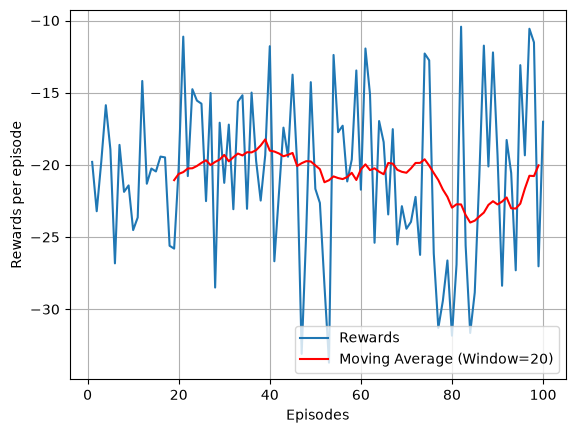

Episode 100 done: steps = 2400, rewards = -19.868844932940796     

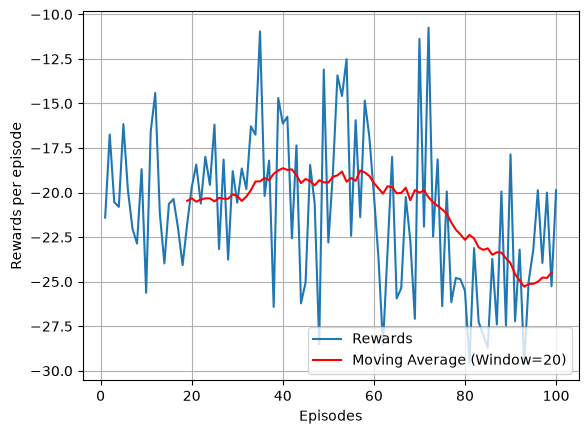


Model                         Return   Bill ($)     Penalty ($)  Total ($)   Time (s)
----------------------------------------------------------------------------------------
Rule-based                    -12.60      12.60            0.00      12.60          -
Q-learning-optimal            -33.32       9.18           24.13      33.32        0.2
Q-learning-aggressive         -27.33      10.53           16.80      27.33        0.3
Dyna-Q-optimal                -34.40       9.07           25.33      34.40        0.6
Dyna-Q-aggressive             -35.43       9.83           25.60      35.43        0.6
DQN-optimal                   -22.54       6.47           16.07      22.54        2.9
DQN-aggressive                -25.22       7.75           17.47      25.22        3.0


In [79]:
# ---------------------------------------------------------------------------
# Policy & Evaluator
# ---------------------------------------------------------------------------

TEST_SEED_OFFSET = 20_000_000

def rule_policy(obs):
    solar, load, price, plugged = obs[5], obs[7], obs[8], obs[4]
    battery = 0 if solar > load else (2 if price >= P.PRICE_PEAK else 1)
    ev = 1 if plugged and price < P.PRICE_PEAK else 0
    appliance = 1 if price <= P.PRICE_MIDDAY else 0
    return battery * 4 + ev * 2 + appliance

def evaluate(policy_fn, n_days=SELECTED_CONFIG["test_days"], seed_offset=TEST_SEED_OFFSET):
    env = EnergyEnv()
    returns, bills, penalties = [], [], []
    for day in range(n_days):
        obs, _ = env.reset(seed=seed_offset + day)
        done, total_ret, bill, penalty = False, 0.0, 0.0, 0.0
        while not done:
            action = int(policy_fn(obs))
            obs, r, done, _, info = env.step(action)
            total_ret += r
            bill += info["cost"]
            penalty += info["penalty"]
        returns.append(total_ret)
        bills.append(bill)
        penalties.append(penalty)
    return {
        "return": np.mean(returns),
        "bill": np.mean(bills),
        "penalty": np.mean(penalties),
        "cost": np.mean(bills) + np.mean(penalties)
    }

# ---------------------------------------------------------------------------
# Training & Evaluation Loop
# ---------------------------------------------------------------------------
results = {}
history = {}
trained_policies = {}

# Evaluate baseline first
results["Rule-based"] = evaluate(rule_policy)

for name, cfg in MODELS.items():
    m_type = cfg["type"]
    params = cfg["params"]
    episodes = SELECTED_CONFIG["Q-learning" if m_type == "ql" else ("Dyna-Q" if m_type == "dynaq" else "DQN")]
    
    seed_scores = []
    history[name] = []
    trained_policies[name] = []
    
    for seed in SEEDS:
        start_time = time.perf_counter()
        if m_type == "ql":
            _, pi, rets = Qlearning(EnergyEnv(), max_episodes=episodes, seed=seed, **params)
            pol = lambda obs, p=pi: int(p[discretise(obs)])
        elif m_type == "dynaq":
            p_clean = {k: v for k, v in params.items() if k in ("alpha", "gamma", "planning_steps")}
            _, pi, rets = DynaQ(EnergyEnv(), max_episodes=episodes, seed=seed, **p_clean)
            pol = lambda obs, p=pi: int(p[discretise(obs)])
        elif m_type == "dqn":
            agent = AgentDQN(EnergyEnv(), gamma=1.0, **params)
            window = max(1, min(episodes, SELECTED_CONFIG["eval_window"])) 
            rets = agent.train(episodes, lambda r: False, criterion_episodes=window, seed=seed)
            pol = lambda obs, a=agent: int(a.policy(obs))
            
        time_elapsed = time.perf_counter() - start_time
        history[name].append(rets)
        trained_policies[name].append(pol)
        
        eval_res = evaluate(pol)
        eval_res["time"] = time_elapsed
        seed_scores.append(eval_res)
    
    results[name] = {
        "return": np.mean([s["return"] for s in seed_scores]),
        "bill": np.mean([s["bill"] for s in seed_scores]),
        "penalty": np.mean([s["penalty"] for s in seed_scores]),
        "cost": np.mean([s["cost"] for s in seed_scores]),
        "time": np.mean([s["time"] for s in seed_scores])
    }

print(f"\n{'Model':<25} {'Return':>10} {'Bill ($)':>10} {'Penalty ($)':>15} {'Total ($)':>10} {'Time (s)':>10}")
print("-" * 88)
for name, m in results.items():
    t_str = f"{m['time']:.1f}" if "time" in m else "-"
    print(f"{name:<25} {m['return']:>10.2f} {m['bill']:>10.2f} {m['penalty']:>15.2f} {m['cost']:>10.2f} {t_str:>10}")